<a href="https://colab.research.google.com/github/Vykhrystenko/ML_FIT_3-9_Vykhrystenko/blob/main/%D0%9B%D0%A0_10_%D0%92%D0%B8%D1%85%D1%80%D0%B8%D1%81%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Вихристенко Владислав
**Група:** 3-9  
**Дата:** 20.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print("x_train_full shape:", x_train_full.shape)
print("y_train_full shape:", y_train_full.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train_full shape: (60000, 28, 28)
y_train_full shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

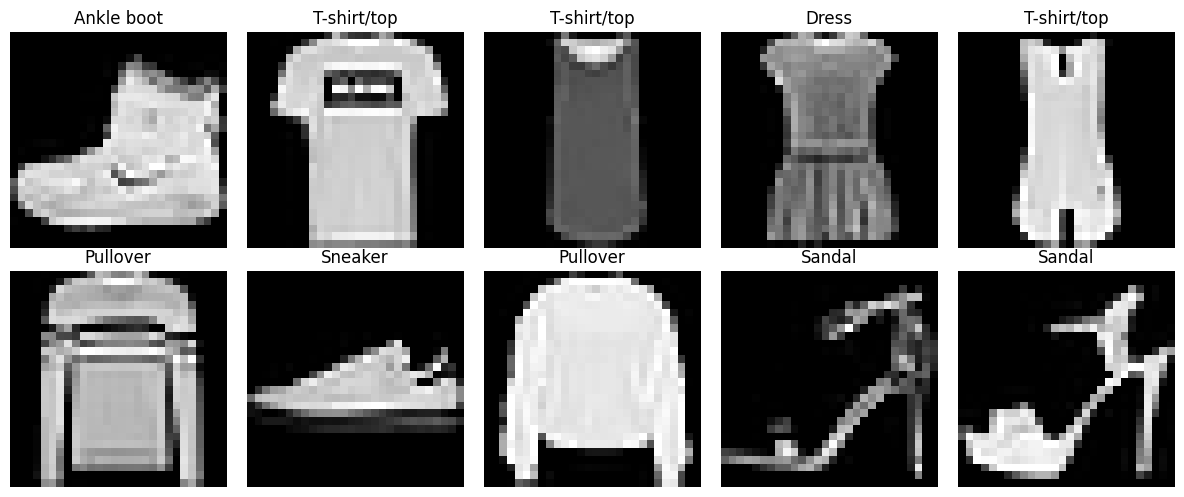

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap='gray')
    plt.title(class_names[y_train_full[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full
)

print("Тип даних:", x_train.dtype)
print("Діапазон значень train:", x_train.min(), "—", x_train.max())
print("Діапазон значень test:", x_test.min(), "—", x_test.max())
print("Розмір навчальної вибірки:", x_train.shape)
print("Розмір валідаційної вибірки:", x_val.shape)

Тип даних: float32
Діапазон значень train: 0.0 — 1.0
Діапазон значень test: 0.0 — 1.0
Розмір навчальної вибірки: (51000, 28, 28)
Розмір валідаційної вибірки: (9000, 28, 28)


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Пояснення вибору гіперпараметрів:

Кількість нейронів (256 та 128): Вхідний вектор після Flatten має розмірність 784 (28 * 28). Поступове звуження (784->256->128->10) дозволяє мережі спочатку виділити достатньо низькорівневих ознак контурів одягу, а на другому шарі узагальнити їх без надмірного роздування кількості параметрів.

Dropout (0.3 та 0.2): Вимикання 30% нейронів на першому ширшому шарі та 20% на другому запобігає перенавчанню, змушуючи мережу не покладатися на окремі пікселі чи вузькі комбінації ознак.

Швидкість навчання (0.001): Стандартне початкове значення для оптимізатора Adam, яке забезпечує швидку та стабільну збіжність на старті навчання, а подальше точне підлаштування ваг контролюється через ReduceLROnPlateau.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7772 - loss: 0.6309 - val_accuracy: 0.8490 - val_loss: 0.4163 - learning_rate: 0.0010
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8434 - loss: 0.4404 - val_accuracy: 0.8712 - val_loss: 0.3533 - learning_rate: 0.0010
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8568 - loss: 0.3967 - val_accuracy: 0.8756 - val_loss: 0.3424 - learning_rate: 0.0010
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8654 - loss: 0.3702 - val_accuracy: 0.8727 - val_loss: 0.3391 - learning_rate: 0.0010
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8712 - loss: 0.3555 - val_accuracy: 0.8697 - val_loss: 0.3580 - learning_rate: 0.0010
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8748 - loss: 0.3401 - val_accuracy: 0.8838 - val_loss: 0.3151 - learning_rate: 0.0010
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8778 - loss: 0.

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save('fashion_mnist_model.keras')

### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

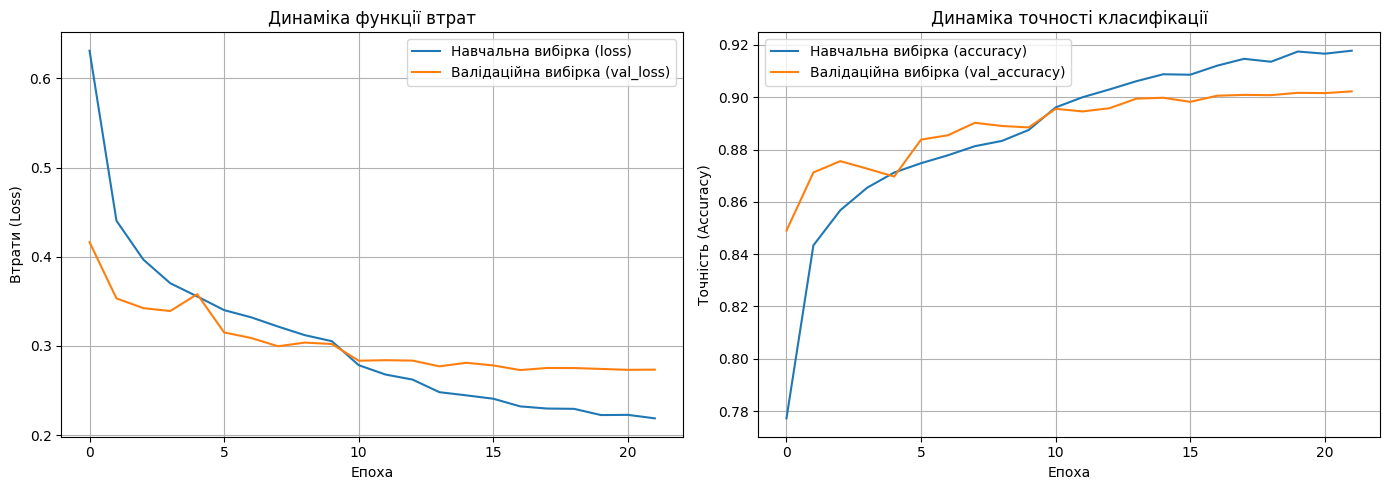

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['loss'], label='Навчальна вибірка (loss)')
ax1.plot(history.history['val_loss'], label='Валідаційна вибірка (val_loss)')
ax1.set_title('Динаміка функції втрат')
ax1.set_xlabel('Епоха')
ax1.set_ylabel('Втрати (Loss)')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['accuracy'], label='Навчальна вибірка (accuracy)')
ax2.plot(history.history['val_accuracy'], label='Валідаційна вибірка (val_accuracy)')
ax2.set_title('Динаміка точності класифікації')
ax2.set_xlabel('Епоха')
ax2.set_ylabel('Точність (Accuracy)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Вимогу >= 0.87 виконано: {test_accuracy >= 0.87}\n")

y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, target_names=class_names))

Test Loss: 0.3076
Test Accuracy: 0.8912
Вимогу >= 0.87 виконано: True

              precision    recall  f1-score   support

 T-shirt/top       0.83      0.86      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.79      0.82      0.81      1000
       Dress       0.89      0.90      0.90      1000
        Coat       0.81      0.81      0.81      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.74      0.68      0.71      1000
     Sneaker       0.94      0.97      0.95      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.96      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

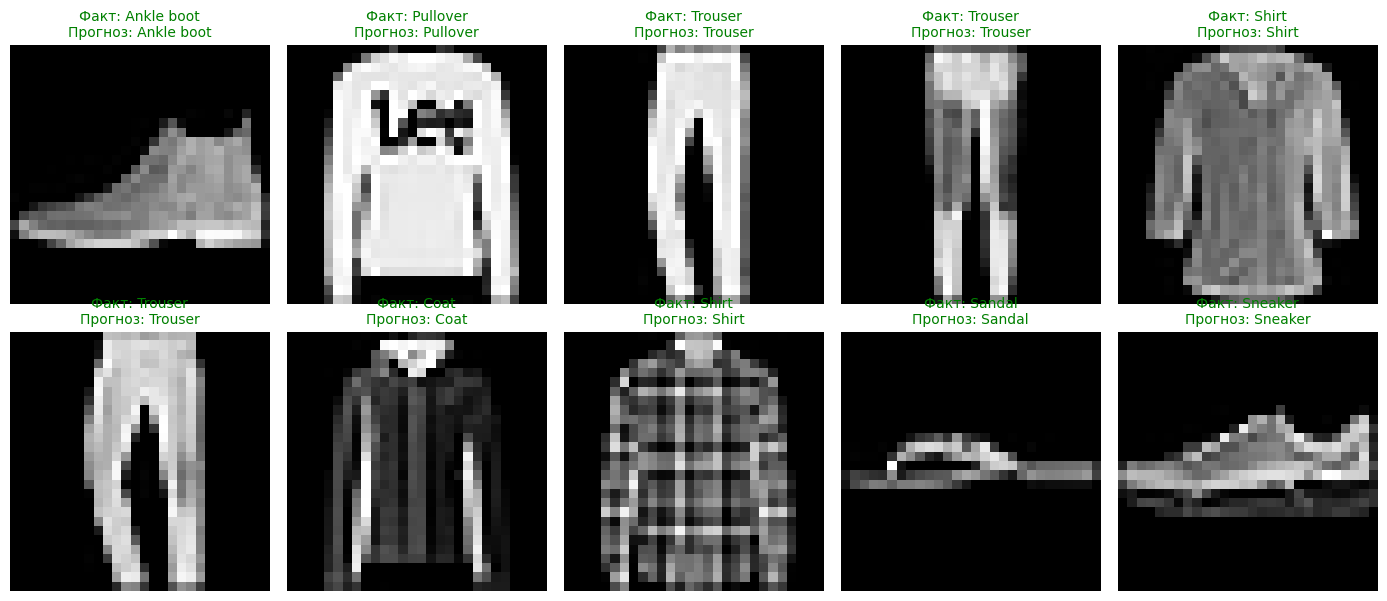

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred[i]]
    color = 'green' if y_test[i] == y_pred[i] else 'red'
    plt.title(f"Факт: {true_label}\nПрогноз: {pred_label}", color=color, fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  

У результаті навчання багатошарового перцептрона з двома прихованими шарами (256 та 128 нейронів) на тестовій вибірці досягнуто точності 0,8912 (89,12%) при значенні функції втрат 0,3076. Встановлену вимогу щодо мінімальної точності (>=0,87) успішно виконано.Згідно зі звітом класифікації, найвищу якість розпізнавання модель демонструє для класів Trouser (F1 = 0,98), Sandal (F1 = 0,98), Bag (F1 = 0,98), Ankle boot (F1 = 0,96) та Sneaker (F1 = 0,95), оскільки ці категорії мають чіткі й унікальні силуети. Найбільша кількість помилок спостерігається для класу Shirt (F1 = 0,71; precision = 0,74; recall = 0,68), а також у парі Pullover (F1 = 0,81) та Coat (F1 = 0,81). Це пояснюється високою візуальною подібністю елементів верхнього одягу на зображеннях низької роздільної здатності (28 * 28 пікселів) та втратою просторових зв'язків після перетворення матриці пікселів в одновимірний вектор шаром Flatten.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
print("Train shape:", x_train.shape, y_train.shape)
print("Validation shape:", x_val.shape, y_val.shape)
print("Test shape (ізольовано):", x_test.shape, y_test.shape)

Train shape: (51000, 28, 28) (51000,)
Validation shape: (9000, 28, 28) (9000,)
Test shape (ізольовано): (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(28, 28)))
    model.add(Flatten())

    num_layers = hp.Int('num_layers', min_value=1, max_value=3)
    for i in range(num_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        dropout_rate = hp.Float(f'dropout_{i}', min_value=0.1, max_value=0.4, step=0.1)
        l2_reg = hp.Choice(f'l2_{i}', values=[0.0, 1e-4, 1e-3])

        model.add(Dense(
            units=units,
            activation='relu',
            kernel_regularizer=l2(l2_reg)
        ))
        model.add(Dropout(dropout_rate))

    model.add(Dense(10, activation='softmax'))

    learning_rate = hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='kt_dir',
    project_name='fashion_mnist_tuning',
    overwrite=True
)

tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.4, 'step': 0.1, 'sampling': 'linear'}
l2_0 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.0001, 0.001], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner_early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
tuner_reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)

tuner.search(
    x_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[tuner_early_stop, tuner_reduce_lr]
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі знайдені гіперпараметри:")
for param, value in best_hps.values.items():
    print(f"  {param}: {value}")

best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

final_early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
final_reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

history_tuned = best_model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[final_early_stop, final_reduce_lr]
)

Trial 3 Complete [00h 01m 29s]
val_accuracy: 0.8972222208976746

Best val_accuracy So Far: 0.8972222208976746
Total elapsed time: 00h 03m 33s
Найкращі знайдені гіперпараметри:
  num_layers: 3
  units_0: 192
  dropout_0: 0.2
  l2_0: 0.001
  learning_rate: 0.001
  units_1: 160
  dropout_1: 0.1
  l2_1: 0.0
  units_2: 32
  dropout_2: 0.1
  l2_2: 0.0


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 192)            │       150,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 160)            │        30,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 187,082 (730.79 KB)

 Trainable params: 187,082 (730.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7526 - loss: 0.8899 - val_accuracy: 0.8478 - val_loss: 0.5726 - learning_rate: 0.0010
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8316 - loss: 0.5921 - val_accuracy: 0.8580 - val_loss: 0.4971 - learning_rate: 0.0010
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8454 - loss: 0.5287 - val_accuracy: 0.8686 - val_loss: 0.4540 - learning_rate: 0.0010
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8512 - loss: 0.5012 - val_accuracy: 0.8686 - val_loss: 0.4352 - learning_rate: 0.0010
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8557 - loss: 0.4777 - val_accuracy: 0.8694 - val_loss: 0.4297 - learning_rate: 0.0010
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8586 - loss: 0.4672 - val_accuracy: 0.8668 - val_loss: 0.4350 - learning_rate: 0.0010
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8611 - loss: 0.4558

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Tuned Test Loss: 0.3533
Tuned Test Accuracy: 0.8920


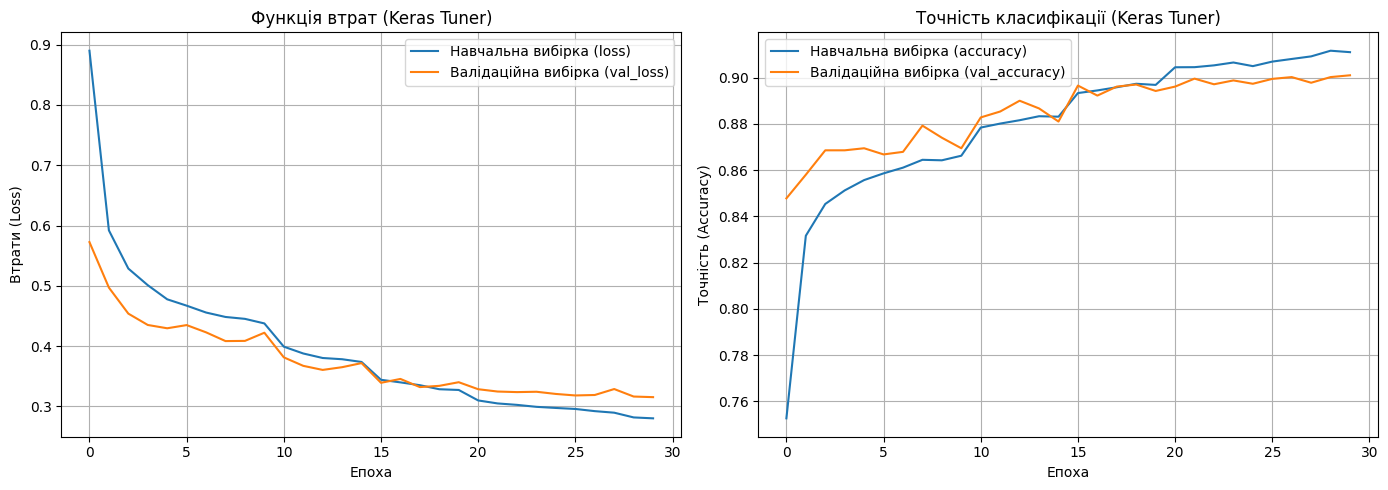

In [17]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
tuned_test_loss, tuned_test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Tuned Test Loss: {tuned_test_loss:.4f}")
print(f"Tuned Test Accuracy: {tuned_test_accuracy:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history_tuned.history['loss'], label='Навчальна вибірка (loss)')
ax1.plot(history_tuned.history['val_loss'], label='Валідаційна вибірка (val_loss)')
ax1.set_title('Функція втрат (Keras Tuner)')
ax1.set_xlabel('Епоха')
ax1.set_ylabel('Втрати (Loss)')
ax1.legend()
ax1.grid(True)

ax2.plot(history_tuned.history['accuracy'], label='Навчальна вибірка (accuracy)')
ax2.plot(history_tuned.history['val_accuracy'], label='Валідаційна вибірка (val_accuracy)')
ax2.set_title('Точність класифікації (Keras Tuner)')
ax2.set_xlabel('Епоха')
ax2.set_ylabel('Точність (Accuracy)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 |3  |
| Кількість нейронів |256,128|192,160,32  |
| Швидкість навчання | 0.001 |0.001  |
| Точність на тестовій вибірці (accuracy) |0.8912  | 0.8920 |
| Втрати на тестовій вибірці (loss) | 0.3076 | 0.3533 |
| Кількість епох навчання | 22(17- найкраща) |30(найкраща - 30)  |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  


Точність у завданні 1: Так, досягнуто тестової точності 0,8912 (поріг >= 0,87 виконано), а EarlyStopping та ReduceLROnPlateau запобігли перенавчанню.

Ефективність оптимізації: Точність трохи зросла (0,8920 проти 0,8912), а кількість параметрів зменшилася зі 235 146 до 187 082. Невеликий приріст пояснюється обмеженням пошуку трьома спробами (max_trials = 3) та вдалою базовою архітектурою.

Найкращі гіперпараметри та відтворюваність: 3 приховані шари (192, 160, 32 нейрони), Dropout (0,2; 0,1; 0,1), L2-регуляризація (0,001 на 1-му шарі) та learning_rate = 0.001. Результат може відрізнятися між запусками через випадковість RandomSearch, ініціалізації ваг, перемішування батчів та роботи Dropout.

Найскладніші класи: Shirt (F1 = 0,71), а також Pullover і Coat (F1 = 0,81) через візуальну схожість силуетів верхнього одягу на зображеннях 28 * 28 та втрату просторових ознак після шару Flatten.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.